# 02 · Customer Segmentation — RFM + K-Means

**Business question:** What kinds of customers does the store have, and how should marketing treat each group?

**Data:** cleaned Online Retail II transactions (see notebook 01).

**Approach:** summarise each customer with **RFM** → log-transform and scale → choose K with the **elbow method** and **silhouette score** → **K-Means** → profile and name each segment → check with **hierarchical clustering**.

- **Recency** = days since the customer's last purchase (lower is better)
- **Frequency** = number of separate orders
- **Monetary** = total amount spent (£)

## Importing the libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder for saving plots (repo: ../images, Kaggle: current folder)
IMG_DIR = '../images' if os.path.isdir('../images') else '.'

## Importing the dataset

In [2]:
# Automatically finds both CSV files under /kaggle/input (Kaggle) or ../data (local) - no manual path copying needed
files_needed = ['online_retail_09_10.csv', 'online_retail_10_11.csv']
paths = {}
for root in ['/kaggle/input', '../data', 'data']:
    for dirname, _, filenames in os.walk(root):
        for filename in filenames:
            if filename in files_needed and filename not in paths:
                paths[filename] = os.path.join(dirname, filename)

if len(paths) < 2:
    print("CSV files not found - attach the 'UCI Online Retail II' dataset under Input (Kaggle) or put them in ../data")
else:
    for f in files_needed:
        print("Found it at:", paths[f])
    # the files start with a hidden BOM character, so 'utf-8-sig' keeps the first column name clean
    dataset = pd.concat([pd.read_csv(paths[f], encoding='utf-8-sig') for f in files_needed], ignore_index=True)
    print(dataset.shape)

Found it at: ../data/online_retail_09_10.csv
Found it at: ../data/online_retail_10_11.csv


(1067371, 8)


## Cleaning the data

In [3]:
# Same cleaning as notebook 01 (explained step by step there)
dataset = dataset.drop_duplicates()                                    # also removes the overlap between the 2 files
dataset['InvoiceNo'] = dataset['InvoiceNo'].astype(str)
dataset['StockCode'] = dataset['StockCode'].astype(str)
dataset['InvoiceDate'] = pd.to_datetime(dataset['InvoiceDate'], format='%m/%d/%Y %H:%M')
dataset = dataset[~dataset['InvoiceNo'].str.startswith('C')]           # cancelled orders
dataset = dataset[(dataset['Quantity'] > 0) & (dataset['UnitPrice'] > 0)]
dataset = dataset.dropna(subset=['CustomerID'])                        # we need to know the customer
dataset = dataset[dataset['StockCode'].str.match(r'^\d')]             # keep real products (drop POST, M, BANK CHARGES...)
dataset['CustomerID'] = dataset['CustomerID'].astype(int)
dataset['Description'] = dataset['Description'].str.strip()           # remove stray spaces in product names
dataset['Revenue'] = dataset['Quantity'] * dataset['UnitPrice']
print(dataset.shape)

(776577, 9)


## Building the RFM table

In [4]:
snapshot_date = dataset['InvoiceDate'].max() + pd.Timedelta(days=1)   # 'today' = the day after the last sale

rfm = dataset.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')).reset_index()

print(rfm.shape)
rfm.head()

(5852, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,3,77352.96
1,12347,2,8,4921.53
2,12348,75,5,1658.40
3,12349,19,3,3678.69
4,12350,310,1,294.40


In [5]:
rfm.describe().round(1)

,CustomerID,Recency,Frequency,Monetary
count,5852.0,5852.0,5852.0,5852.0
mean,15319.7,200.2,6.3,2916.7
std,1714.9,208.5,12.7,14306.9
min,12346.0,1.0,1.0,3.0
25%,13837.8,25.0,1.0,339.6
50%,15320.5,95.0,3.0,856.0
75%,16802.2,379.0,7.0,2241.0
max,18287.0,739.0,373.0,580987.0


RFM values are **very skewed** (most customers spend little, a few spend hundreds of thousands). K-Means uses distances, so a few giants would dominate. We take `log(1 + x)` to compress the scale, then standardise.

In [6]:
X = rfm.iloc[:, [1, 2, 3]].values      # Recency, Frequency, Monetary
X = np.log1p(X)

## Feature Scaling

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X = sc.fit_transform(X)

## Using the elbow method to find the optimal number of clusters

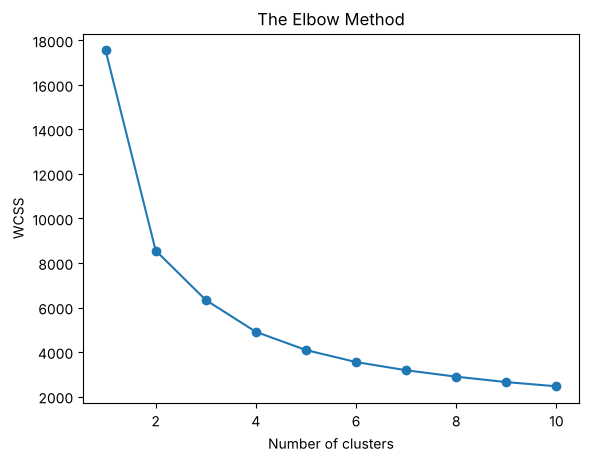

In [8]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.savefig(f'{IMG_DIR}/02_elbow.png', dpi=120, bbox_inches='tight')
plt.show()

## Checking with the silhouette score
Silhouette = (b − a) / max(a, b): how much closer a customer is to its own cluster than to the nearest other cluster. Higher is better (max 1).

In [9]:
from sklearn.metrics import silhouette_score
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    print("K = {}  silhouette = {:.3f}".format(k, silhouette_score(X, labels)))

K = 2  silhouette = 0.438


K = 3  silhouette = 0.347


K = 4  silhouette = 0.365


K = 5  silhouette = 0.343


K = 6  silhouette = 0.335


K = 7  silhouette = 0.303


K = 8  silhouette = 0.295


**Choosing K = 4.** K = 2 has the highest silhouette, but it only splits customers into "good" and "bad" — too coarse to act on. The elbow bends around 3–4, and K = 4 scores higher than K = 3, while giving four segments marketing can treat differently.

## Training the K-Means model on the dataset

In [10]:
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)
rfm['Cluster'] = y_kmeans

## Profiling the segments

In [11]:
profile = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Recency_median=('Recency', 'median'),
    Frequency_median=('Frequency', 'median'),
    Monetary_median=('Monetary', 'median'),
    Revenue=('Monetary', 'sum'))
profile['% customers'] = (profile['Customers'] / profile['Customers'].sum() * 100).round(1)
profile['% revenue'] = (profile['Revenue'] / profile['Revenue'].sum() * 100).round(1)
profile

,Customers,Recency_median,Frequency_median,Monetary_median,Revenue,% customers,% revenue
Cluster,,,,,,,
0,1455,184.0,4.0,1455.270,2878425.82,24.9,16.9
1,1182,16.0,13.0,4904.980,12517347.03,20.2,73.3
2,1969,401.0,1.0,275.880,624376.23,33.6,3.7
3,1246,24.0,3.0,720.355,1048418.89,21.3,6.1


## Naming the segments
Names are assigned from the numbers (not by hand), so they stay correct even if cluster numbers change.

In [12]:
names = {}
champions = profile['Frequency_median'].idxmax()            # buy most often
lost = profile['Recency_median'].idxmax()                   # haven't bought for the longest
names[champions] = 'Champions'
names[lost] = 'Lost'
remaining = [c for c in profile.index if c not in names]
at_risk = profile.loc[remaining, 'Recency_median'].idxmax()  # of the other two, the less recent one
names[at_risk] = 'At Risk'
names[[c for c in remaining if c != at_risk][0]] = 'New / Promising'

rfm['Segment'] = rfm['Cluster'].map(names)
profile['Segment'] = profile.index.map(names)
profile.set_index('Segment').drop(columns='Revenue').sort_values('% revenue', ascending=False)

,Customers,Recency_median,Frequency_median,Monetary_median,% customers,% revenue
Segment,,,,,,
Champions,1182,16.0,13.0,4904.980,20.2,73.3
At Risk,1455,184.0,4.0,1455.270,24.9,16.9
New / Promising,1246,24.0,3.0,720.355,21.3,6.1
Lost,1969,401.0,1.0,275.880,33.6,3.7


## Visualising the clusters

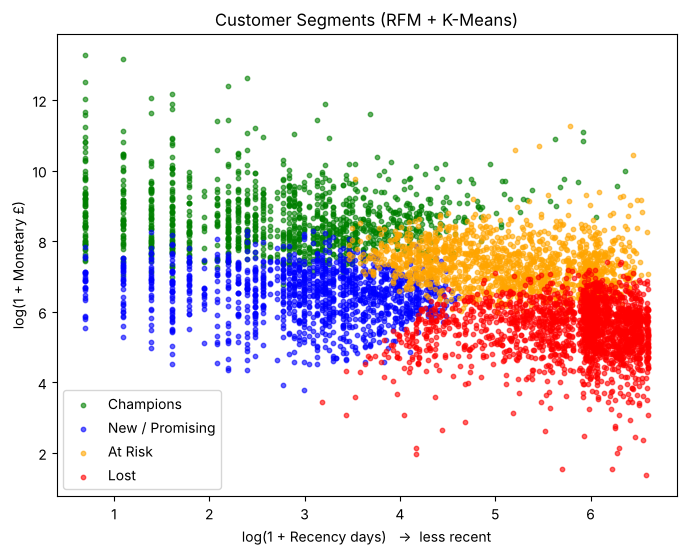

In [13]:
X_plot = np.log1p(rfm.iloc[:, [1, 2, 3]].values)   # log scale (not standardised) for readable axes
colors = {'Champions': 'green', 'New / Promising': 'blue', 'At Risk': 'orange', 'Lost': 'red'}

plt.figure(figsize=(8, 6))
for seg, col in colors.items():
    mask = (rfm['Segment'] == seg).values
    plt.scatter(X_plot[mask, 0], X_plot[mask, 2], s=10, c=col, label=seg, alpha=0.6)
plt.title('Customer Segments (RFM + K-Means)')
plt.xlabel('log(1 + Recency days)   →  less recent')
plt.ylabel('log(1 + Monetary £)')
plt.legend()
plt.savefig(f'{IMG_DIR}/02_segments.png', dpi=120, bbox_inches='tight')
plt.show()

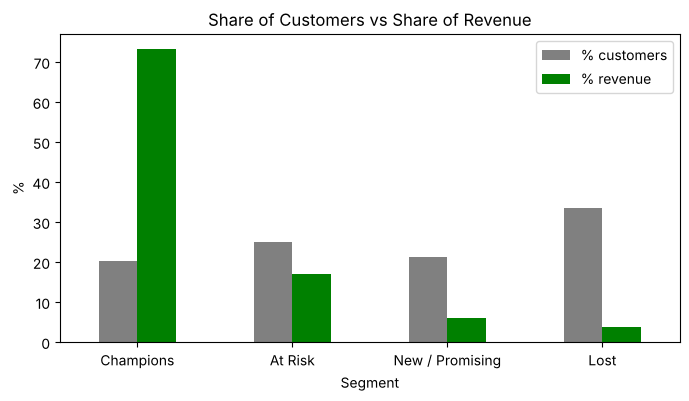

In [14]:
seg_share = profile.set_index('Segment')[['% customers', '% revenue']].sort_values('% revenue', ascending=False)
seg_share.plot(kind='bar', figsize=(8, 4), color=['grey', 'green'])
plt.title('Share of Customers vs Share of Revenue')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.savefig(f'{IMG_DIR}/02_segment_share.png', dpi=120, bbox_inches='tight')
plt.show()

## Cross-check with Hierarchical Clustering (dendrogram)
A dendrogram on a random sample of 1,000 customers (the full set is too large to draw).

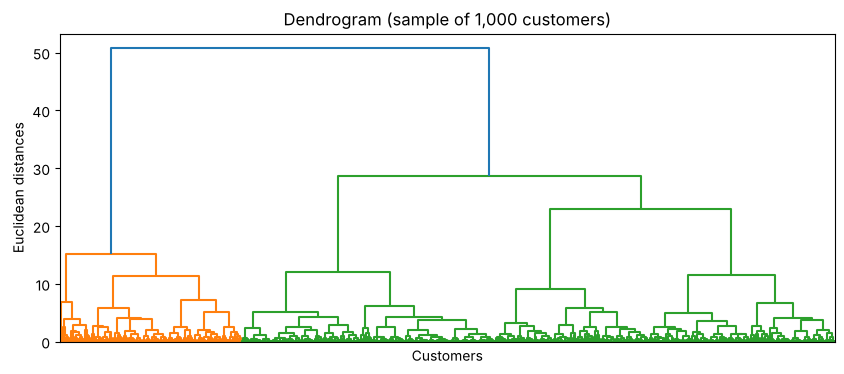

In [15]:
import scipy.cluster.hierarchy as sch
sample_idx = np.random.RandomState(0).choice(len(X), 1000, replace=False)
plt.figure(figsize=(10, 4))
dendrogram = sch.dendrogram(sch.linkage(X[sample_idx], method='ward'), no_labels=True)
plt.title('Dendrogram (sample of 1,000 customers)')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.savefig(f'{IMG_DIR}/02_dendrogram.png', dpi=120, bbox_inches='tight')
plt.show()

In [16]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X[sample_idx])
from sklearn.metrics import adjusted_rand_score
print("Agreement between K-Means and Hierarchical on the sample (Adjusted Rand Index): {:.2f}".format(
    adjusted_rand_score(y_kmeans[sample_idx], y_hc)))

Agreement between K-Means and Hierarchical on the sample (Adjusted Rand Index): 0.73


## Business recommendations

| Segment | Who they are | Action |
|---|---|---|
| **Champions** | Recent, frequent, big spenders | Loyalty programme, early access, account manager for wholesalers. Protect at all costs. |
| **New / Promising** | Bought recently, only a few times | Onboarding emails, second-order discount to build the habit. |
| **At Risk** | Used to buy, gone quiet for months | Win-back campaign, personal offer, ask for feedback. |
| **Lost** | One small order, long ago | Low-cost reactivation only; don't overspend. |

See the profile table above for each segment's real share of customers and revenue.

**Next:** 03 — which products are bought together (Apriori).